In [53]:
from sound_simulation import *
from beamforming import *
from sensor_array import *
from scene import *
from util import *
from psd_estimation import *
from plot_utils import *
from cropac import *

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, Audio

In [54]:
fig_width = 11

duration = 5
sr = 48000
c = 344
fmin = 750
fmax = 6000

sensor_array = array_circle8()
noise = prepare_audio("../samples/meas1_ambience.wav", duration, sr, False)
# noise = pink_diffuse_noise(duration * sr, sensor_array.positions, sr)
noise = normalize_channels(noise)

target_position = np.array([100, 0, 10])
scene = scene_stationary(duration, sr, target_position)
#target_sound = prepare_drone_audio(scene, sensor_array, "../samples/mavic4_steady.wav", duration, sr, db2lin(65-60))
#target_sound = prepare_drone_audio(scene, sensor_array, "../samples/mini3_steady.wav", duration, sr, db2lin(58-60))
target_sound = prepare_drone_audio(scene, sensor_array, "../samples/neo_flight.wav", duration, sr, db2lin(68-60))

audio = noise + target_sound

N = 2**10
step = N//2
window = np.hanning(N)**0.5
VN, f, validf = valid_frequency_bins(fmin, fmax, N, sr)
SN, tidx, snaps = stft(audio, window, step, validf)
_, _, target_snaps = stft(target_sound, window, step, validf)
_, _, noise_snaps = stft(noise, window, step, validf)
k = 2 * np.pi * f / c

target_udir = target_position / np.linalg.norm(target_position)
target_steer = create_steering_vectors(create_distance_vectors(target_udir[None,:], sensor_array.positions), k[:,None])

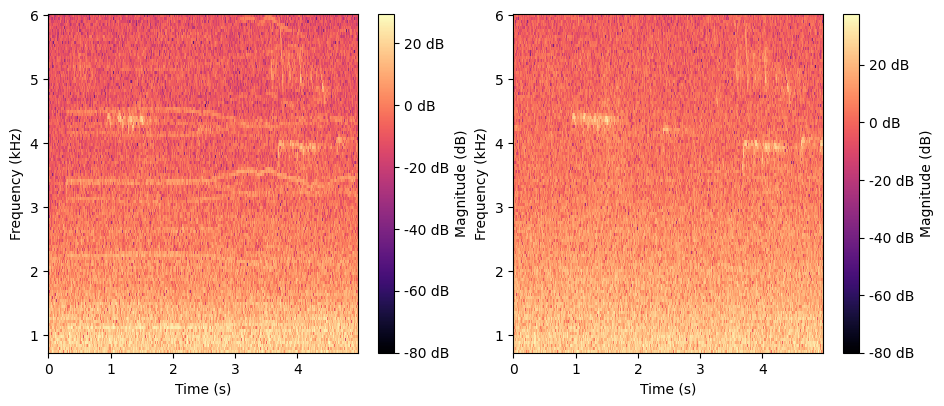

In [ ]:


w_das = wideband_das_weights(target_steer)
das_snaps = np.array([beamform_wideband(s.T, w_das) for s in snaps])

sdas = istft(das_snaps, window, tidx, validf)
ch0 = istft(snaps[:,0,:], window, tidx, validf)

display(Audio(sdas, rate=sr))
display(Audio(ch0, rate=sr))

fig = plt.figure(figsize=(fig_width, fig_width*0.4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
plot_spectrogram(ax1, f, tidx/sr, lin2db(das_snaps).T)
plot_spectrogram(ax2, f, tidx/sr, lin2db(snaps[:,0,:]).T)

Text(0.5, 1.0, 'Pure Signal')

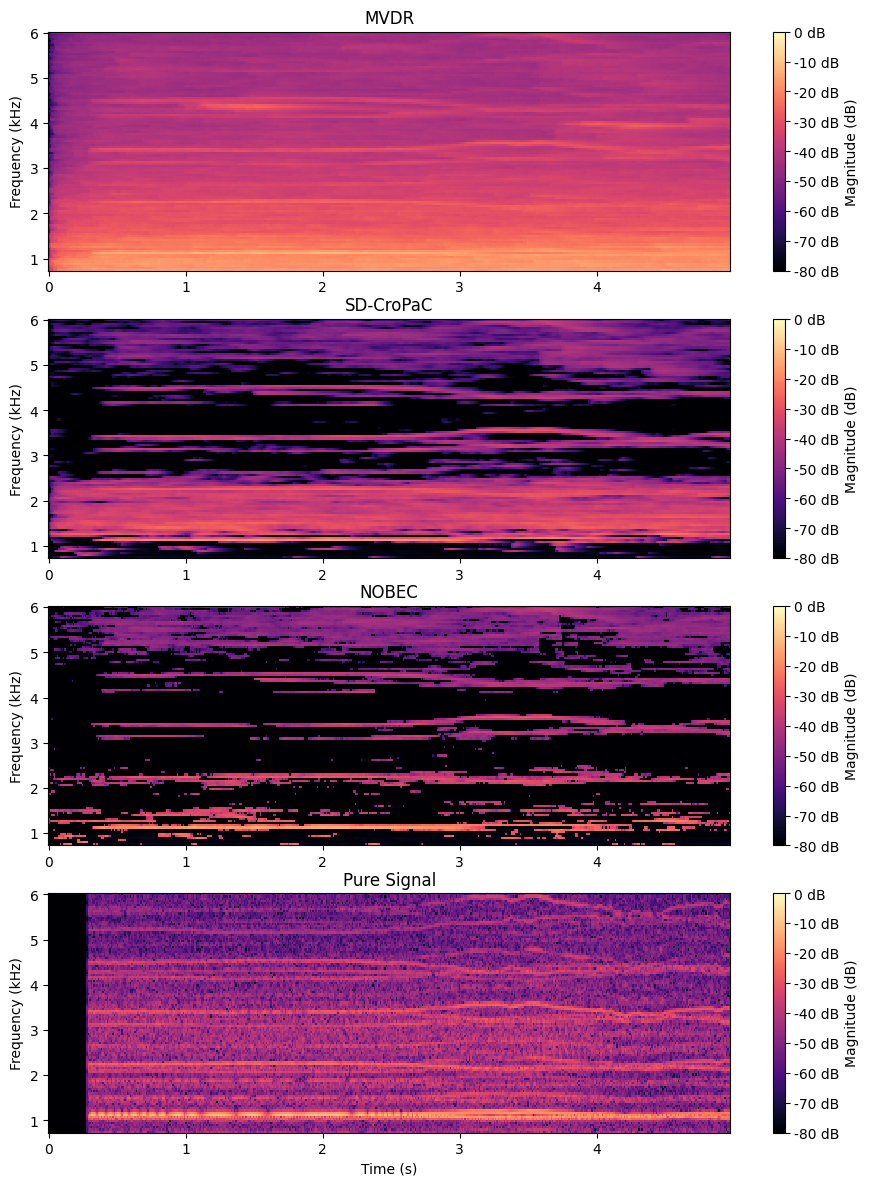

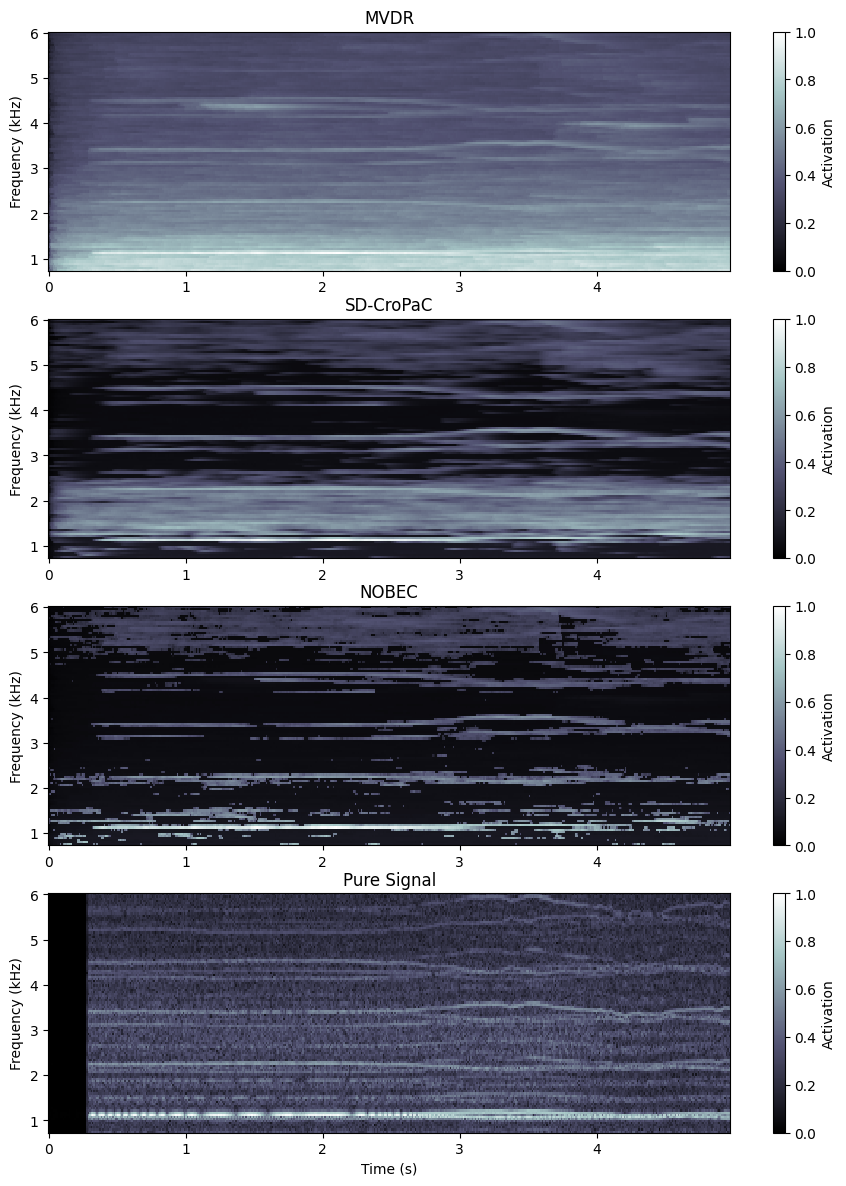

In [59]:
params = PSDEParams(
    sensor_array.positions,
    target_udir, k,
    target_steer,
    compute_covariance_matrices(snaps[0]))

threshold = -120
LNR = 0

das_estimator = DAS_PSDE(params)
ch0_estimator = CH0_PSDE(params)
mvdr_estimator = MVDR_PSDE(db2lin(LNR), params)
cropac_estimator = CroPaC_Gain(db2lin(threshold/2), params)
dobec_estimator = DOBEC_PSDE(db2lin(threshold), params)
nobec_estimator = NOBEC_PSDE(db2lin(LNR), db2lin(threshold), params, order=2)

Sx = np.array([compute_covariance_matrices(snap) for snap in snaps])
Sx = fb_average(Sx, sensor_array.positions)
smooth_Sx = time_average(Sx, smoothing_alpha(sr*0.1, step, 0.5))

ch0_psd = np.array([ch0_estimator.estimate_psd(s) for s in Sx])
das_psd = np.array([das_estimator.estimate_psd(s) for s in Sx])
mvdr_psd = np.array([mvdr_estimator.update_and_estimate(params, s) for s in smooth_Sx])
cropac_gain = np.array([cropac_estimator.estimate_psd(s) for s in smooth_Sx])
dobec_psd = np.array([dobec_estimator.estimate_psd(s) for s in smooth_Sx])
nobec_psd = np.array([nobec_estimator.update_and_estimate(params, s) for s in smooth_Sx])

noise_level = np.max(pow2db(ch0_psd))

cropac_gain = time_average(cropac_gain, smoothing_alpha(sr*0.025, step, 0.5))
cropac_psd = mvdr_psd * (cropac_gain**2)

St = np.array([compute_covariance_matrices(snap) for snap in target_snaps])
target_psd = np.array([das_estimator.estimate_psd(s) for s in St])

psa = psd_to_sound(nobec_psd, das_snaps, window, tidx, validf)
display(Audio(psa, rate=sr))

fig = plt.figure(figsize=(fig_width, fig_width*1.3))
ax3 = fig.add_subplot(411)
ax5 = fig.add_subplot(412)
ax6 = fig.add_subplot(413)
ax8 = fig.add_subplot(414)
plot_spectrogram(ax3, f, tidx/sr, pow2db(mvdr_psd).T - noise_level, vmin=-80, vmax=0, x_label=False)
plot_spectrogram(ax5, f, tidx/sr, pow2db(cropac_psd).T - noise_level, vmin=-80, vmax=0, x_label=False)
plot_spectrogram(ax6, f, tidx/sr, pow2db(nobec_psd).T - noise_level, vmin=-80, vmax=0, x_label=False)
plot_spectrogram(ax8, f, tidx/sr, pow2db(target_psd).T - noise_level, vmin=-80, vmax=0,)
ax3.set_title("MVDR")
ax5.set_title("SD-CroPaC")
ax6.set_title("NOBEC")
ax8.set_title("Pure Signal")

# fig = plt.figure(figsize=(fig_width, fig_width*0.5))
# ax = fig.add_subplot(111)
# ax.plot(f, (pow2db(cropac_psd) - noise_level)[SN//2])
# ax.plot(f, (pow2db(target_psd) - noise_level)[SN//2])
# ax.plot(f, (pow2db(nobec_psd) - noise_level)[SN//2])

compress = lambda x: np.pow(x, 0.15)

cropac_gain = time_average(cropac_gain, smoothing_alpha(sr*0.025, step, 0.5))
cropac_psd = mvdr_psd * (cropac_gain**2)

St = np.array([compute_covariance_matrices(snap) for snap in target_snaps])
target_psd = np.array([das_estimator.estimate_psd(s) for s in St])

psa = psd_to_sound(nobec_psd, das_snaps, window, tidx, validf)
display(Audio(psa, rate=sr))

def plot_gram(ax, f, t, S_db, vmin=0, vmax=1, log_freq=False, y_label=True, x_label=True):
    # Convert frequency to kHz for display
    y = f / 1000.0
    mesh = ax.pcolormesh(t, y, S_db/np.max(S_db), shading='nearest', cmap="bone", vmin=vmin, vmax=vmax)
    if y_label:
        ax.set_ylabel("Frequency (kHz)")
    if x_label:
        ax.set_xlabel("Time (s)")
    if log_freq:
        ax.set_yscale("log")
    cbar = plt.colorbar(mesh, ax=ax, format="%.1f")
    cbar.set_label("Activation")

fig = plt.figure(figsize=(fig_width, fig_width*1.3))
ax3 = fig.add_subplot(411)
ax5 = fig.add_subplot(412)
ax6 = fig.add_subplot(413)
ax8 = fig.add_subplot(414)
plot_gram(ax3, f, tidx/sr, compress(mvdr_psd).T, x_label=False)
plot_gram(ax5, f, tidx/sr, compress(cropac_psd).T, x_label=False)
plot_gram(ax6, f, tidx/sr, compress(nobec_psd).T, x_label=False)
plot_gram(ax8, f, tidx/sr, compress(target_psd).T)
ax3.set_title("MVDR")
ax5.set_title("SD-CroPaC")
ax6.set_title("NOBEC")
ax8.set_title("Pure Signal")
